# Practice Lab: Neural Networks for Handwritten Digit Recognition, Multiclass 

In this exercise, you will use a neural network to recognize the hand-written digits 0-9.


# Outline
- [ 1 - Packages ](#1)
- [ 2 - ReLU Activation](#2)
- [ 3 - Softmax Function](#3)
  - [ Exercise 1](#ex01)
- [ 4 - Neural Networks](#4)
  - [ 4.1 Problem Statement](#4.1)
  - [ 4.2 Dataset](#4.2)
  - [ 4.3 Model representation](#4.3)
  - [ 4.4 Tensorflow Model Implementation](#4.4)
  - [ 4.5 Softmax placement](#4.5)
    - [ Exercise 2](#ex02)


<a name="1"></a>
## 1 - Packages 

First, let's run the cell below to import all the packages that you will need during this assignment.
- [numpy](https://numpy.org/) is the fundamental package for scientific computing with Python.
- [matplotlib](http://matplotlib.org) is a popular library to plot graphs in Python.
- [tensorflow](https://www.tensorflow.org/) a popular platform for machine learning.

In [41]:
import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
np.set_printoptions(precision=5,suppress=True)

In [42]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import linear, relu, sigmoid
%matplotlib widget
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

from public_tests import * 

from autils import *
from lab_utils_softmax import plt_softmax
np.set_printoptions(precision=2)

<a name="2"></a>
## 2 - ReLU Activation
This week, a new activation was introduced, the Rectified Linear Unit (ReLU). 
$$ a = max(0,z) \quad\quad\text {# ReLU function} $$

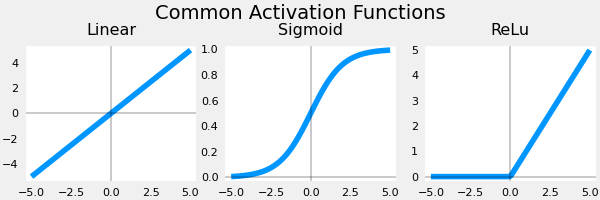

In [43]:
plt_act_trio()

<img align="right" src="./images/C2_W2_ReLu.png"     style=" width:380px; padding: 10px 20px; " >
The example from the lecture on the right shows an application of the ReLU. In this example, the derived "awareness" feature is not binary but has a continuous range of values. The sigmoid is best for on/off or binary situations. The ReLU provides a continuous linear relationship. Additionally it has an 'off' range where the output is zero.

讲座右侧的例子展示了ReLU（线性整流函数）的一个应用。在这个例子中，推导出的“awareness”（意识）特征不是二元的，而是具有连续的值域。Sigmoid函数最适合于开/关或二元情况。而ReLU提供了一个连续的线性关系。此外，它还具有一个“关闭”范围，在该范围内输出为零。

The "off" feature makes the ReLU a Non-Linear activation. Why is this needed? This enables multiple units to contribute to to the resulting function without interfering. This is examined more in the supporting optional lab. 

ReLU的“关闭”特性使其成为一种非线性激活函数。为什么需要这种非线性呢？这是因为这允许多个单元对最终函数做出贡献而不会相互干扰。这一点在支持性的可选实验室实验中会有更深入的探讨。

<a name="3"></a>
## 3 - Softmax Function
A multiclass neural network generates N outputs. One output is selected as the predicted answer. In the output layer, a vector $\mathbf{z}$ is generated by a linear function which is fed into a softmax function. The softmax function converts $\mathbf{z}$  into a probability distribution as described below. After applying softmax, each output will be between 0 and 1 and the outputs will sum to 1. They can be interpreted as probabilities. The larger inputs to the softmax will correspond to larger output probabilities.

一个多类别神经网络会生成 N 个输出，其中一个输出被选为预测答案。在输出层，一个线性函数会生成一个向量 $\mathbf{z}$，该向量随后被输入到softmax函数中。softmax函数会将 $\mathbf{z}$ 转换为如下所述的概率分布。应用softmax之后，每个输出值都会介于0和1之间，并且所有输出值的和将为1。它们可以被解释为概率。输入到softmax中的较大值将对应较大的输出概率。
<center>  <img  src="./images/C2_W2_NNSoftmax.PNG" width="600" />  

The softmax function can be written:

softmax函数可以表示为：
$$a_j = \frac{e^{z_j}}{ \sum_{k=0}^{N-1}{e^{z_k} }} \tag{1}$$

Where $z = \mathbf{w} \cdot \mathbf{x} + b$ and N is the number of feature/categories in the output layer.  

其中，$z = \mathbf{w} \cdot \mathbf{x} + b$，N是输出层中特征/类别的数量。

<a name="ex01"></a>
### Exercise 1
Let's create a NumPy implementation:

In [44]:
# UNQ_C1
# GRADED CELL: my_softmax

def my_softmax(z):  
    """ Softmax converts a vector of values to a probability distribution.
    Args:
      z (ndarray (N,))  : input data, N features
    Returns:
      a (ndarray (N,))  : softmax of z
    """    
    ### START CODE HERE ### 
    ez = np.exp(z)
    a = ez/np.sum(ez)
    ### END CODE HERE ### 
    return a

In [45]:
z = np.array([1., 2., 3., 4.])
a = my_softmax(z)
atf = tf.nn.softmax(z)
print(f"my_softmax(z):         {a}")
print(f"tensorflow softmax(z): {atf}")

# BEGIN UNIT TEST  
test_my_softmax(my_softmax)
# END UNIT TEST  

my_softmax(z):         [0.03 0.09 0.24 0.64]
tensorflow softmax(z): [0.03 0.09 0.24 0.64]
 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    One implementation uses for loop to first build the denominator and then a second loop to calculate each output.
    
```python
def my_softmax(z):  
    N = len(z)
    a =                     # initialize a to zeros 
    ez_sum =                # initialize sum to zero
    for k in range(N):      # loop over number of outputs             
        ez_sum +=           # sum exp(z[k]) to build the shared denominator      
    for j in range(N):      # loop over number of outputs again                
        a[j] =              # divide each the exp of each output by the denominator   
    return(a)
```
<details>
  <summary><font size="3" color="darkgreen"><b>Click for code</b></font></summary>
   
```python
def my_softmax(z):  
    N = len(z)
    a = np.zeros(N)
    ez_sum = 0
    for k in range(N):                
        ez_sum += np.exp(z[k])       
    for j in range(N):                
        a[j] = np.exp(z[j])/ez_sum   
    return(a)

Or, a vector implementation:

def my_softmax(z):  
    ez = np.exp(z)              
    a = ez/np.sum(ez)           
    return(a)

```


Below, vary the values of the `z` inputs. Note in particular how the exponential in the numerator magnifies small differences in the values. Note as well that the output values sum to one.

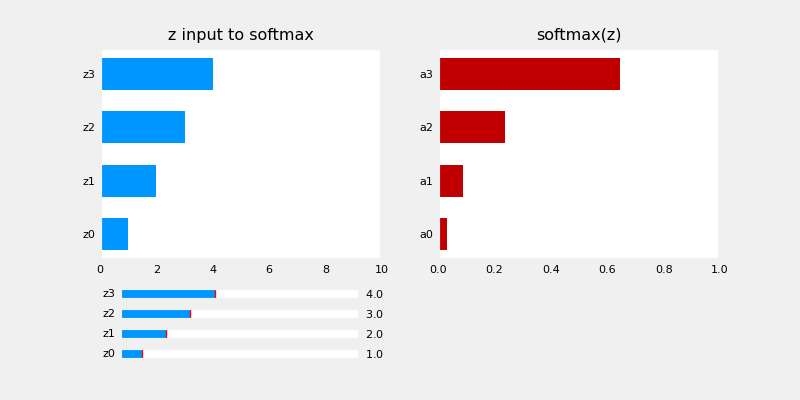

In [46]:
plt.close("all")
plt_softmax(my_softmax)

<a name="4"></a>
## 4 - Neural Networks

In last weeks assignment, you implemented a neural network to do binary classification. This week you will extend that to multiclass classification. This will utilize the softmax activation.

在上周的作业中，你实现了一个用于二分类的神经网络。本周，你将把它扩展到多分类，这将使用softmax激活函数。

<a name="4.1"></a>
### 4.1 Problem Statement

In this exercise, you will use a neural network to recognize ten handwritten digits, 0-9. This is a multiclass classification task where one of n choices is selected. Automated handwritten digit recognition is widely used today - from recognizing zip codes (postal codes) on mail envelopes to recognizing amounts written on bank checks. 

在这个练习中，你将使用神经网络来识别0到9这十个手写数字。这是一个多分类任务，需要从n个选项中选择一个。如今，自动手写数字识别已被广泛应用——从识别邮件信封上的邮政编码到识别银行支票上的金额。


<a name="4.2"></a>
### 4.2 Dataset

You will start by loading the dataset for this task. 

你将首先为这个任务加载数据集。

- The `load_data()` function shown below loads the data into variables `X` and `y`

- 下方展示的`load_data()` 函数将数据加载到变量 `X` 和 `y` 中。

- The data set contains 5000 training examples of handwritten digits $^1$.  

- 数据集包含5000个手写数字的训练样本$^1$。

    - Each training example is a 20-pixel x 20-pixel grayscale image of the digit. 
    - 每个训练样本是该数字的一个20像素x20像素的灰度图像。
        - Each pixel is represented by a floating-point number indicating the grayscale intensity at that location. 
        - 每个像素由一个浮点数表示，该浮点数指示该位置的灰度强度。
        - The 20 by 20 grid of pixels is “unrolled” into a 400-dimensional vector. 
        - 20x20的像素网格被“展开”成一个400维的向量。
        - Each training examples becomes a single row in our data matrix `X`. 
        - 每个训练样本在我们的数据矩阵 `X` 中成为一行。
        - This gives us a 5000 x 400 matrix `X` where every row is a training example of a handwritten digit image.
        - 这给我们一个5000x400的矩阵`X`，其中每一行都是一个手写数字图像的训练样本。

$$X = 
\left(\begin{array}{cc} 
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\ 
--- (x^{(m)}) --- 
\end{array}\right)$$ 

- The second part of the training set is a 5000 x 1 dimensional vector `y` that contains labels for the training set
- 训练集的第二部分是一个5000 x 1维的向量`y`，它包含了训练集的标签。
    - `y = 0` if the image is of the digit `0`, `y = 4` if the image is of the digit `4` and so on.
    - 如果图像是数字`0`，则`y = 0`；如果图像是数字`4`，则`y = 4`；以此类推。

$^1$<sub> This is a subset of the MNIST handwritten digit dataset（这是MNIST手写数字数据集的一个子集。） (http://yann.lecun.com/exdb/mnist/)</sub>

In [47]:
# load dataset
X, y = load_data()

#### 4.2.1 View the variables（查看变量）
Let's get more familiar with your dataset.  

让我们更深入地了解你的数据集。
- A good place to start is to print out each variable and see what it contains.
- 一个好的开始是打印出每个变量，看看它们包含什么内容。

The code below prints the first element in the variables `X` and `y`.  

下面的代码打印了变量 `X` 和 `y` 中的第一个元素。

In [48]:
print ('The first element of X is: ', X[0])

The first element of X is:  [ 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.    0.    0.    0.    0.    0.   -0.   -0.01 -0.02
 -0.02 -0.02 -0.02 -0.02 -0.    0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.   -0.01 -0.03  0.08  0.27  0.27  0.28  0.27  0.22
  0.03 -0.01  0.    0.    0.    0.    0.    0.    0.    0.   -0.   -0.01
  0.08  0.38  0.86  1.    0.97  0.93  1.    0.96  0.45 -0.01 -0.    0.
  0.    0.    0.    0.    0.   -0.   -0.03  0.1   0.64  1.03  0.85  0.54
  0.34  0.27  0.67  1.01  0.9   0.1  -0.02  0.    0.    0.    0.    0.
 -0.    0.01  0.18  0.79  0.97  0.46  0.07 -0.   -0.04 -0.05  0.16  0.9
  1.05  0.15 -0.02  0.    0.    0.    0.

In [49]:
print ('The first element of y is: ', y[0,0])
print ('The last element of y is: ', y[-1,0])

The first element of y is:  0
The last element of y is:  9


#### 4.2.2 Check the dimensions of your variables

Another way to get familiar with your data is to view its dimensions. Please print the shape of `X` and `y` and see how many training examples you have in your dataset.

In [50]:
print ('The shape of X is: ' + str(X.shape))
print ('The shape of y is: ' + str(y.shape))

The shape of X is: (5000, 400)
The shape of y is: (5000, 1)


#### 4.2.3 Visualizing the Data（数据可视化）

You will begin by visualizing a subset of the training set. 
你将从可视化训练集的一个子集开始。
- In the cell below, the code randomly selects 64 rows from `X`, maps each row back to a 20 pixel by 20 pixel grayscale image and displays the images together.
- 在下面的单元格中，代码随机选择了`X` 中的64行，将每一行映射回一个20像素乘20像素的灰度图像，并将这些图像一起显示。
- The label for each image is displayed above the image 
- 每个图像的标签显示在图像上方。

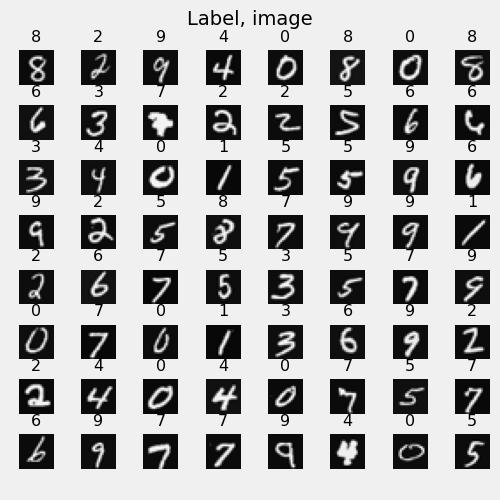

In [51]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]

#fig.tight_layout(pad=0.5)
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Display the label above the image
    ax.set_title(y[random_index,0])
    ax.set_axis_off()
    fig.suptitle("Label, image", fontsize=14)

<a name="4.3"></a>
### 4.3 Model representation（模型表示）

The neural network you will use in this assignment is shown in the figure below. 

你在本次任务中将使用的神经网络如下图所示。

- This has two dense layers with ReLU activations followed by an output layer with a linear activation. 
- 该网络包含两个具有ReLU激活函数的全连接（dense）层，后面是一个具有线性激活函数的输出层。
    - Recall that our inputs are pixel values of digit images.
    - 请记住，我们的输入是数字图像的像素值。
    - Since the images are of size $20\times20$, this gives us $400$ inputs  
    - 由于图像的大小为20×20，因此我们有400个输入。 
    
<img src="images/C2_W2_Assigment_NN.png" width="600" height="450">

- The parameters have dimensions that are sized for a neural network with $25$ units in layer 1, $15$ units in layer 2 and $10$ output units in layer 3, one for each digit.

- 参数的维度是为一个具有第1层 $25$ 个单元、第2层 $15$ 个单元和第3层 $10$ 个输出单元（每个数字一个）的神经网络设置的。

    - Recall that the dimensions of these parameters is determined as follows:
    - 请记住，这些参数的维度确定如下：
        - If network has $s_{in}$ units in a layer and $s_{out}$ units in the next layer, then 
        - 如果网络的一层有 $s_{in}$ 个单元，而下一层有 $s_{out}$ 个单元，则
            - $W$ will be of dimension $s_{in} \times s_{out}$.
            - $W$  的维度将是$s_{in} \times s_{out}$。
            - $b$ will be a vector with $s_{out}$ elements
            - $b$ 将是一个具有 $s_{out}$ 个元素的向量。
  
    - Therefore, the shapes of `W`, and `b`,  are 
    - 因此，`W` 和 `b` 的形状是
        - layer1: The shape of `W1` is (400, 25) and the shape of `b1` is (25,)
        - 第1层：`W1` 的形状是(400, 25)，`b1` 的形状是(25,)
        - layer2: The shape of `W2` is (25, 15) and the shape of `b2` is: (15,)
        - 第2层：`W2` 的形状是(25, 15)，`b2` 的形状是(15,)
        - layer3: The shape of `W3` is (15, 10) and the shape of `b3` is: (10,)
        - 第3层：`W3` 的形状是(15, 10)，`b3` 的形状是(10,)
        
>**Note:** The bias vector `b` could be represented as a 1-D (n,) or 2-D (n,1) array. Tensorflow utilizes a 1-D representation and this lab will maintain that convention: 

>**注意:**  偏置向量 `b` 可以表示为1维（n,）或2维（n,1）数组。TensorFlow使用1维表示，并且本实验将保持这一约定：
               

<a name="4.4"></a>
### 4.4 Tensorflow Model Implementation（TensorFlow模型实现）


Tensorflow models are built layer by layer. A layer's input dimensions ($s_{in}$ above) are calculated for you. You specify a layer's *output dimensions* and this determines the next layer's input dimension. The input dimension of the first layer is derived from the size of the input data specified in the `model.fit` statement below. 

TensorFlow模型是通过逐层构建而成的。每一层的输入维度（上述的$s_{in}$）是为你自动计算的。您需要指定一个层的输出维度，这将决定下一层的输入维度。第一层的输入维度是从`model.fit` 语句中指定的输入数据大小派生而来的。

>**Note:** It is also possible to add an input layer that specifies the input dimension of the first layer. For example:  
`tf.keras.Input(shape=(400,)),    #specify input shape`  


>**注意:**  还可以添加一个输入层来明确指定第一层的输入维度。例如：
`tf.keras.Input(shape=(400,)),    #specify input shape` 

We will include that here to illuminate some model sizing.

为了更清楚地说明模型尺寸，我们在这里也会包含这种方式。

<a name="4.5"></a>
### 4.5 Softmax placement（Softmax函数的位置）
As described in the lecture and the optional softmax lab, numerical stability is improved if the softmax is grouped with the loss function rather than the output layer during training. This has implications when *building* the model and *using* the model.  

正如在课程和可选的softmax实验中所描述的，如果在训练期间将softmax与损失函数而不是输出层组合在一起，可以提高数值稳定性。这对构建模型和使用模型都有影响。

Building（构建模型时）:  
* The final Dense layer should use a 'linear' activation. This is effectively no activation. 
* 最后一层全连接层（Dense layer）应该使用'linear'激活函数。这实际上是不使用任何激活函数。
* The `model.compile` statement will indicate this by including `from_logits=True`.
* 在`model.compile` 语句中，通过包含`from_logits=True` 来指示这一点。例如：
`loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) `  
* This does not impact the form of the target. In the case of SparseCategorialCrossentropy, the target is the expected digit, 0-9.
* 这不会影响目标的形式。在使用SparseCategoricalCrossentropy时，目标是期望的数字，范围是0-9。

Using the model（使用模型时）:
* The outputs are not probabilities. If output probabilities are desired, apply a softmax function.
* 模型的输出不是概率。如果需要输出概率，请应用softmax函数。

<a name="ex02"></a>
### Exercise 2

Below, using Keras [Sequential model](https://keras.io/guides/sequential_model/) and [Dense Layer](https://keras.io/api/layers/core_layers/dense/) with a ReLU activation to construct the three layer network described above.

下面，我们将使用Keras的Sequential模型和Dense层，并为其添加ReLU激活函数，以构建上述描述的三层网络。

In [53]:
# UNQ_C2
# GRADED CELL: Sequential model
tf.random.set_seed(1234) # for consistent results
model = Sequential(
    [               
        ### START CODE HERE ### 
        tf.keras.Input(shape=(400,)),
        Dense(25, activation="relu", name="L1"),
        Dense(15, activation="relu", name="L2"),
        Dense(10, activation="linear", name="L3")
        ### END CODE HERE ### 
    ], name = "my_model" 
)
model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True))

In [55]:
model.summary()

Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
L1 (Dense)                   (None, 25)                10025     
_________________________________________________________________
L2 (Dense)                   (None, 15)                390       
_________________________________________________________________
L3 (Dense)                   (None, 10)                160       
Total params: 10,575
Trainable params: 10,575
Non-trainable params: 0
_________________________________________________________________


<details>
  <summary><font size="3" color="darkgreen"><b>Expected Output (Click to expand)</b></font></summary>
The `model.summary()` function displays a useful summary of the model. Note, the names of the layers may vary as they are auto-generated unless the name is specified.    
    
```
Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 25)                10025     
_________________________________________________________________
L2 (Dense)                   (None, 15)                390       
_________________________________________________________________
L3 (Dense)                   (None, 10)                160       
=================================================================
Total params: 10,575
Trainable params: 10,575
Non-trainable params: 0
_________________________________________________________________
```

<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    
```python
tf.random.set_seed(1234)
model = Sequential(
    [               
        ### START CODE HERE ### 
        tf.keras.Input(shape=(400,)),     # @REPLACE 
        Dense(25, activation='relu', name = "L1"), # @REPLACE 
        Dense(15, activation='relu',  name = "L2"), # @REPLACE  
        Dense(10, activation='linear', name = "L3"),  # @REPLACE 
        ### END CODE HERE ### 
    ], name = "my_model" 
)
``` 

In [56]:
# BEGIN UNIT TEST     
test_model(model, 10, 400)
# END UNIT TEST     

All tests passed!


The parameter counts shown in the summary correspond to the number of elements in the weight and bias arrays as shown below.

摘要中显示的参数数量对应于权重和偏置数组中元素的数量。

Let's further examine the weights to verify that tensorflow produced the same dimensions as we calculated above.

让我们进一步检查权重，以验证TensorFlow生成的维度是否与我们上面计算的一致。

In [57]:
[layer1, layer2, layer3] = model.layers

In [58]:
#### Examine Weights shapes
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 10), b3 shape = (10,)


**Expected Output**
```
W1 shape = (400, 25), b1 shape = (25,)  
W2 shape = (25, 15), b2 shape = (15,)  
W3 shape = (15, 10), b3 shape = (10,)
```

The following code:
以下代码：
* defines a loss function, `SparseCategoricalCrossentropy` and indicates the softmax should be included with the  loss calculation by adding `from_logits=True`)
* 定义了一个损失函数`SparseCategoricalCrossentropy`，并通过添加`from_logits=True` 来指示在计算损失时应包括softmax（实际上是在模型输出为logits时，损失函数会自行应用softmax的逆运算，即log-softmax，来进行计算）。
* defines an optimizer. A popular choice is Adaptive Moment (Adam) which was described in lecture.
* 定义了一个优化器。一个常用的选择是自适应优化器（Adam），这在课程中已经介绍过。

In [59]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
)

history = model.fit(
    X,y,
    epochs=40
)

Epoch 1/40
157/157 [==============================] - 1s 3ms/step - loss: 1.7094
Epoch 2/40
157/157 [==============================] - 0s 3ms/step - loss: 0.7480
Epoch 3/40
157/157 [==============================] - 0s 3ms/step - loss: 0.4428
Epoch 4/40
157/157 [==============================] - 0s 3ms/step - loss: 0.3463
Epoch 5/40
157/157 [==============================] - 0s 3ms/step - loss: 0.2977
Epoch 6/40
157/157 [==============================] - 0s 3ms/step - loss: 0.2630
Epoch 7/40
157/157 [==============================] - 0s 3ms/step - loss: 0.2361
Epoch 8/40
157/157 [==============================] - 0s 3ms/step - loss: 0.2131
Epoch 9/40
157/157 [==============================] - 0s 3ms/step - loss: 0.2004
Epoch 10/40
157/157 [==============================] - 0s 3ms/step - loss: 0.1805
Epoch 11/40
157/157 [==============================] - 0s 3ms/step - loss: 0.1692
Epoch 12/40
157/157 [==============================] - 0s 3ms/step - loss: 0.1580
Epoch 13/40
157/157 [====

#### Epochs and batches  迭代次数（Epochs）和批次（Batches）
In the `compile` statement above, the number of `epochs` was set to 100. This specifies that the entire data set should be applied during training 100 times.  During training, you see output describing the progress of training that looks like this:

在上面的 `compile` 语句中，`epochs` 的数量被设置为100。这表示在训练过程中，整个数据集应该被训练100次。在训练期间，您会看到描述训练进度的输出，如下所示：

```
Epoch 1/100
157/157 [==============================] - 0s 1ms/step - loss: 2.2770
```
The first line, `Epoch 1/100`, describes which epoch the model is currently running. For efficiency, the training data set is broken into 'batches'. The default size of a batch in Tensorflow is 32. There are 5000 examples in our data set or roughly 157 batches. The notation on the 2nd line `157/157 [====` is describing which batch has been executed.
第一行`Epoch 1/100`描述了模型当前正在运行的迭代次数。为了提高效率，训练数据集被分成多个 `batches`。在TensorFlow中，批次的默认大小是32。在我们的数据集中有5000个样本，大约分成157个批次。第二行的符号 `157/157 [====` 描述了已经执行的批次。

#### Loss  (cost)  损失（成本）
In course 1, we learned to track the progress of gradient descent by monitoring the cost. Ideally, the cost will decrease as the number of iterations of the algorithm increases. Tensorflow refers to the cost as `loss`. Above, you saw the loss displayed each epoch as `model.fit` was executing. The [.fit](https://www.tensorflow.org/api_docs/python/tf/keras/Model) method returns a variety of metrics including the loss. This is captured in the `history` variable above. This can be used to examine the loss in a plot as shown below.

在第一课中，我们学习了通过监控成本来跟踪梯度下降法的进展。理想情况下，随着算法迭代次数的增加，成本会降低。TensorFlow将成本称为`loss`。在上面，您看到了在执行`model.fit` 时每个迭代周期显示的损失。[.fit] 方法返回包括损失在内的多种指标。这些指标被捕获到上面的 `history` 变量中。可以使用这个变量在图表中检查损失，如下所示。

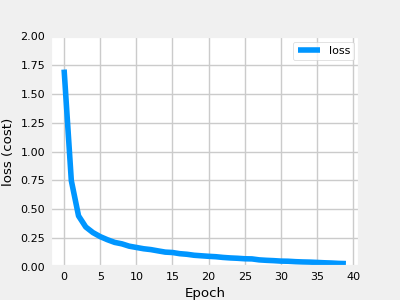

In [60]:
plot_loss_tf(history)

#### Prediction  预测
To make a prediction, use Keras `predict`. Below, X[1015] contains an image of a two.

要进行预测，请使用Keras的 `predict` 方法。在下面的示例中，X[1015]包含了一个数字2的图像。

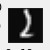

 predicting a Two: 
[[ -7.99  -2.23   0.77  -2.41 -11.66 -11.15  -9.53  -3.36  -4.42  -7.17]]
 Largest Prediction index: 2


In [61]:
image_of_two = X[1015]
display_digit(image_of_two)

prediction = model.predict(image_of_two.reshape(1,400))  # prediction

print(f" predicting a Two: \n{prediction}")
print(f" Largest Prediction index: {np.argmax(prediction)}")

The largest output is prediction[2], indicating the predicted digit is a '2'. If the problem only requires a selection, that is sufficient. Use NumPy [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) to select it. If the problem requires a probability, a softmax is required:


最大的输出是prediction[2]，这表明预测的数字是'2'。如果问题只需要选择一个结果，那么这就足够了。可以使用NumPy的argmax函数来选择它。如果问题需要得到概率，那么就需要应用softmax函数：

In [62]:
prediction_p = tf.nn.softmax(prediction)

print(f" predicting a Two. Probability vector: \n{prediction_p}")
print(f"Total of predictions: {np.sum(prediction_p):0.3f}")

 predicting a Two. Probability vector: 
[[0.   0.04 0.9  0.04 0.   0.   0.   0.01 0.01 0.  ]]
Total of predictions: 1.000


To return an integer representing the predicted target, you want the index of the largest probability. This is accomplished with the Numpy [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) function.

要返回一个表示预测目标的整数，你需要最大概率的索引。这可以通过NumPy的 [argmax] 函数来实现。 

In [63]:
yhat = np.argmax(prediction_p)

print(f"np.argmax(prediction_p): {yhat}")

np.argmax(prediction_p): 2


Let's compare the predictions vs the labels for a random sample of 64 digits. This takes a moment to run.

让我们比较一下64个随机数字样本的预测结果与实际标签。这可能需要一会儿时间来运行。

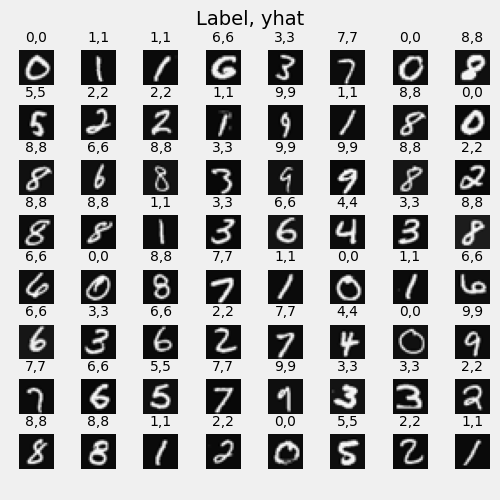

In [64]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Predict using the Neural Network
    prediction = model.predict(X[random_index].reshape(1,400))
    prediction_p = tf.nn.softmax(prediction)
    yhat = np.argmax(prediction_p)
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{yhat}",fontsize=10)
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=14)
plt.show()

Let's look at some of the errors.  

让我们来看一些出错的情况。

>Note: increasing the number of training epochs can eliminate the errors on this data set.

>Note: 增加训练迭代次数可以消除这个数据集上的错误。

15 errors out of 5000 images


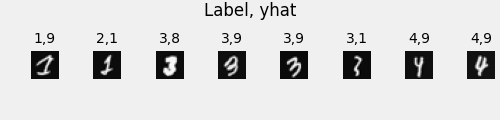

In [66]:
print( f"{display_errors(model,X,y)} errors out of {len(X)} images")

### Congratulations!
You have successfully built and utilized a neural network to do multiclass classification.

###  恭喜！
您已经成功构建并利用了一个神经网络来进行多类分类。